# Task 4: Game Title Detection (image classification)
Target `label`, **submitted as a number per `datacard.txt`**: 0 = 7-11 Knights, 1 = FiveN, 2 = Free Fried, 3 = PUBE, 4 = Roblock.
Metric: **macro F1**. Pretrained models are allowed for this task only.

**Pipeline:** load → EDA → train-only damage augmentation + Mixup/CutMix → **5-fold** fine-tuning with EMA weights, each fold keeping its **final EMA weights** (no epoch picked on validation) → one more model on **100% of the labelled images** → test = ½ fold average + ½ full-data model → flip TTA → save OOF + test probabilities.

**Train-only design.** This notebook fine-tunes **DINOv3 ViT-7B/16 with LoRA** on a B200 GPU (bf16, Section 3); it was run twice with training seeds 7 and 8 (`TRAIN_SEED`, same seed-42 folds) through `run_lora_4gpu.sh`, which spreads the 5 folds + full-data model of each seed over 4 GPUs. Weights are gated on HuggingFace: accept the licence and log in (`HF_TOKEN`, set in the terminal, never in the notebook) first. The saved probabilities are in `results/` (`*_seed7`, `*_seed8`), and **`task4_final_blend.ipynb` averages the two runs into the submitted `task4` column**. The earlier version (v1: other backbones and an ensemble, `*_v1` notebooks) is not used.

**Data:** images come from the Google Drive link in `README.md` (downloaded automatically on Kaggle; locally `train.csv`, `test.csv`, `train/`, `test/` next to the notebook).

**Kaggle output is kept small:** images and checkpoints live in `/tmp` (not saved); `/kaggle/working` only gets the CSV files and probabilities.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, re, gc, glob, zipfile, time, math, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, timm
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
from scipy.optimize import minimize
from timm.utils import ModelEmaV3
from timm.optim import create_optimizer_v2
if os.name != 'nt':   # Python 3.14 starts DataLoader workers with forkserver, which cannot pickle classes defined in a notebook
    import multiprocessing as mp; mp.set_start_method('fork', force=True)

# Data source: local (train.csv, test.csv, train/, test/ next to this notebook) or Kaggle.
# On Kaggle the task folder only has README.md + datacard.txt, so the images are downloaded
# from the Google Drive link in README.md (turn on Internet in the notebook settings).
KAGGLE = '/kaggle/input'   # competition data is mounted somewhere below this (path differs by how it is attached)
ON_KAGGLE = os.path.exists(KAGGLE) and os.environ.get('NOT_KAGGLE') != '1'   # some GPU servers run Kaggle's Docker image: the run script sets NOT_KAGGLE=1
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'     # only small files go here (it becomes the Kaggle output)
CKPT_DIR = '/tmp' if ON_KAGGLE else '.'               # checkpoints are not part of the Kaggle output
if ON_KAGGLE:
    root = '/tmp/task4_data'                          # ~650 MB of images: kept out of /kaggle/working
    if not glob.glob(f'{root}/**/train.csv', recursive=True):
        os.makedirs(root, exist_ok=True)
        readme = f'{KAGGLE}/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/04_image_classification/README.md'
        if not os.path.exists(readme):   # fallback if the competition is mounted under another path
            readme = glob.glob(f'{KAGGLE}/**/04_image_classification/README.md', recursive=True)[0]
        print('README:', readme)
        file_id = re.search(r'/d/([\w-]+)', open(readme).read()).group(1)
        os.system('pip install -q gdown')
        import gdown
        z = gdown.download(id=file_id, output=f'{root}/data.zip', quiet=False)
        zipfile.ZipFile(z).extractall(root); os.remove(z)
    DATA = os.path.dirname(glob.glob(f'{root}/**/train.csv', recursive=True)[0])
else:
    DATA = '.'
assert all(os.path.exists(f'{DATA}/{p}') for p in ('train.csv', 'test.csv', 'train', 'test')), f'data not found in {DATA}'
print('data from:', os.path.abspath(DATA))
SEED = 42   # the first run's folds, so the new backbone's OOF lines up with the saved ones
S = '' if SEED == 42 else f'_s{SEED}'   # file-name suffix, so result files of different seeds never mix
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
N_GPU = torch.cuda.device_count()
# Label ids 0-4 come from datacard.txt (the PDF's string labels are NOT the submission format)
NAMES = ['7-11 Knights', 'FiveN', 'Free Fried', 'PUBE', 'Roblock']
torch.manual_seed(SEED); np.random.seed(SEED)

# csv columns: id (PLY…/ANS…), file_name (image), label (0-4; empty in test)
train = pd.read_csv(f'{DATA}/train.csv'); test = pd.read_csv(f'{DATA}/test.csv')
assert set(train['label']) == set(range(5)), f'unexpected labels: {set(train["label"])}'
assert test['id'].str.startswith('ANS').all(), 'test.csv must map submission ids (ANS…) to images'
train['y'] = train['label'].astype(int)
for d in (train, test): d['img'] = d['file_name'].str.removesuffix('.jpg')
print(train.shape, test.shape, '| GPUs:', N_GPU, [torch.cuda.get_device_name(i) for i in range(N_GPU)])

data from: /root/mac/run_cpe342-task4-dino7b-lora
(31546, 5) (25889, 4) | GPUs: 1 ['NVIDIA B200']


## 1. EDA

           game  images  share
0  7-11 Knights   12429  0.394
1         FiveN    4407  0.140
2    Free Fried    5596  0.177
3          PUBE    5926  0.188
4       Roblock    3188  0.101
image size: (230, 120) (width × height)


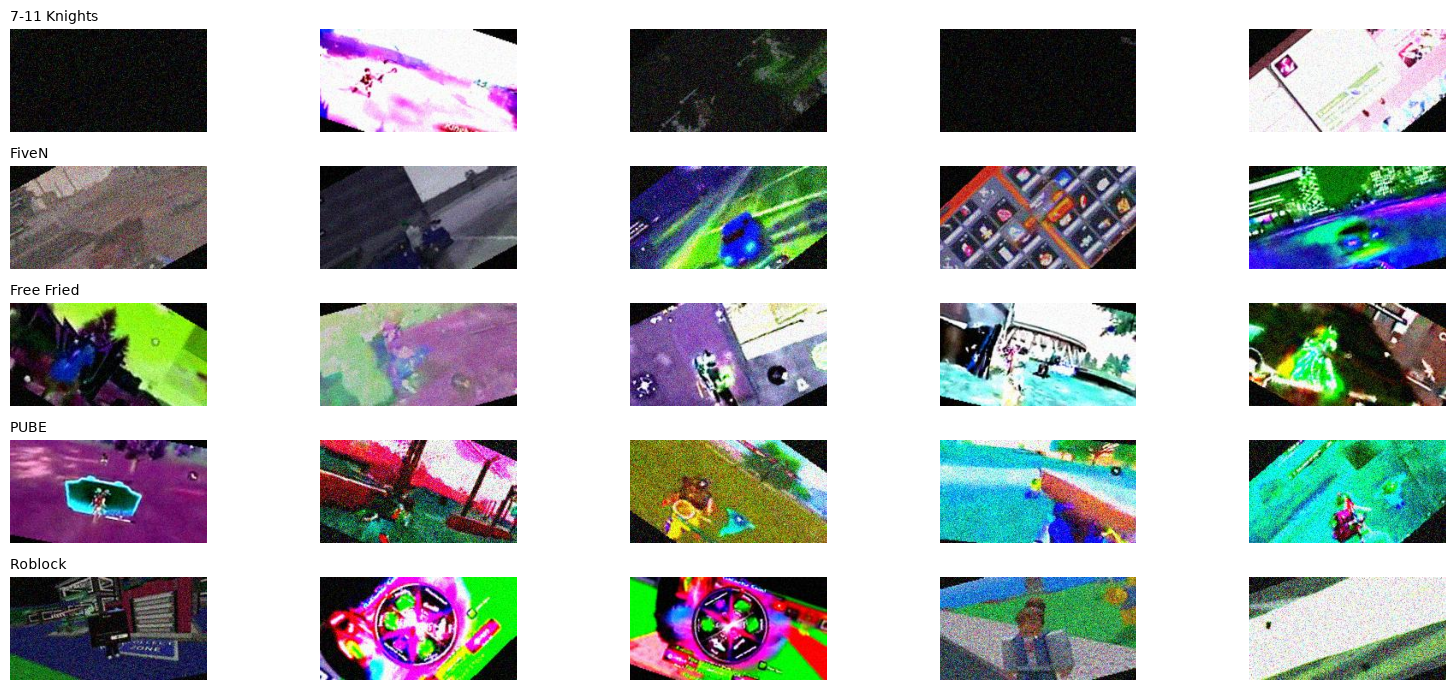

In [2]:
cnt = train['y'].value_counts().sort_index()
print(pd.DataFrame({'game': NAMES, 'images': cnt.values, 'share': (cnt / cnt.sum()).round(3).values}))
print('image size:', Image.open(f'{DATA}/train/{train.img[0]}.jpg').size, '(width × height)')

fig, axes = plt.subplots(5, 5, figsize=(16, 7))
for r, k in enumerate(range(5)):
    for c, i in enumerate(train[train.y == k].sample(5, random_state=SEED).img):
        axes[r, c].imshow(Image.open(f'{DATA}/train/{i}.jpg')); axes[r, c].axis('off')
    axes[r, 0].set_title(NAMES[k], loc='left', fontsize=10)
plt.tight_layout(); plt.show()

### Key insights
1. **Imbalanced classes:** 7-11 Knights is ~39% of the images and Roblock only ~10%. Macro F1 weights every game equally, so the small classes matter as much as the big one. Class weights are tuned on out-of-fold predictions only.
2. **Small, wide, damaged images** (230×120): rotated with black corners, colour-shifted or inverted, very dark, over-saturated or noisy, in train and test alike.
3. **Train-only design.** Every augmentation setting and every model decision is made from train images only: test images are only predicted, never measured or compared with train. The augmentation reproduces damage that train itself contains (rotation/shift with black corners in most train images, brightness from very dark to bright, colour casts, grey images, sensor noise); a train-only check (Section 1 of `task4_final_blend.ipynb`) shows brightness, saturation and colour cast of the augmented train images stay inside train's own 1–99% range for 89–96% of the images (the augmented images are smoother and get black corners more often than train).
4. Images are resized keeping the ~2:1 aspect ratio (160×320 for the CNN, 192×384 for the ViT), so objects are not squashed as in a 224×224 square.

## 2. Data pipeline + damage augmentation (train-only)

validation rows per fold: [6310, 6309, 6309, 6309, 6309] | test 25889 | batch 32


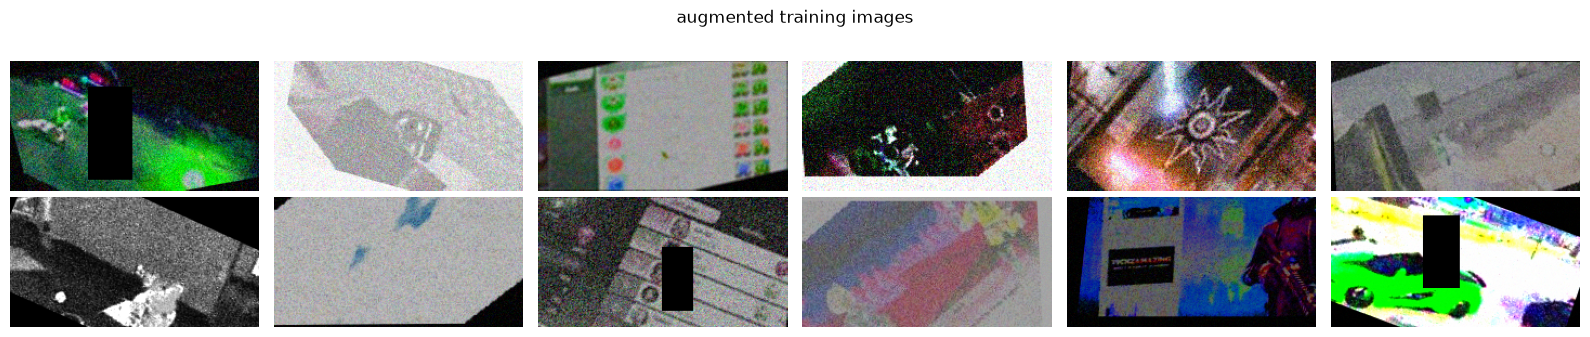

In [3]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
YIQ = torch.tensor([[0.299, 0.587, 0.114], [0.596, -0.274, -0.322], [0.211, -0.523, 0.312]])

class Imgs(Dataset):
    def __init__(self, names, ys, folder): self.names, self.ys, self.folder = list(names), ys, folder
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        x = torch.from_numpy(np.array(Image.open(f'{DATA}/{self.folder}/{self.names[i]}.jpg').convert('RGB'))).permute(2, 0, 1)
        return x, (-1 if self.ys is None else self.ys[i])

def corrupt(x, g, hud=0.):
    # the damage seen in the data: rotation, hue shift/inversion, grayscale, saturation, darkness, noise, blur, occlusion
    n, dev = x.size(0), x.device
    u = lambda *s: torch.rand(n, *s, device=dev, generator=g)
    flip = u() < .5; x[flip] = x[flip].flip(-1)
    ang = (u() * 2 - 1) * math.radians(30) * (u() < .6)
    sc = 1 + (u() * .25 - .1)
    if hud: sc = torch.where(u() < hud, 1 / (.6 + .3 * u()), sc)   # only draws when on, so evaluation corruption stays identical to earlier runs               # HUD dropout: zoom into the centre 60-90%, so menus/minimaps at the edges are cut off
    sh = torch.tan((u() * 2 - 1) * math.radians(8))                     # shear
    tx, ty = (u() * 2 - 1) * .16, (u() * 2 - 1) * .16                    # shift up to ±8% of the image
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    a = x.size(2) / x.size(3)                                           # aspect-correct rotation on the 2:1 image
    theta = torch.stack([torch.stack([cos, (-sin + sh * cos) * a, tx], 1),
                         torch.stack([sin / a, cos + sh * sin, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), align_corners=False)   # black corners
    # hue shift by any angle: turn the chroma (I, Q) plane of the YIQ colour space, keep brightness Y
    h = u() * 2 * math.pi * (u() < .5); c, s, one, z = torch.cos(h), torch.sin(h), torch.ones(n, device=dev), torch.zeros(n, device=dev)
    rot = torch.stack([torch.stack([one, z, z], 1), torch.stack([z, c, -s], 1), torch.stack([z, s, c], 1)], 1)
    M = torch.linalg.inv(YIQ.to(dev)) @ rot @ YIQ.to(dev)
    x = torch.einsum('nij,njhw->nihw', M, x).clamp(0, 1)
    inv = u() < .15; x[inv] = 1 - x[inv]
    gray = x.mean(1, keepdim=True)
    to_gray = u() < .1; x[to_gray] = gray[to_gray].expand(-1, 3, -1, -1)
    x = gray + (x - gray) * (.5 + 1.5 * u(1, 1, 1))                                   # saturation
    x = x * (.35 + .95 * u(1, 1, 1)); x = x.clamp(0, 1) ** (.6 + .9 * u(1, 1, 1))     # brightness + gamma
    blur = u() < .2
    if blur.any(): x[blur] = F.avg_pool2d(x[blur], 3, 1, 1)
    x = x + torch.randn(x.shape, device=dev, generator=g) * .12 * u(1, 1, 1) * (u(1, 1, 1) < .6)   # sensor noise
    # random erasing: one black box covering 2-20% of the image, on a quarter of the images
    H_, W_ = x.shape[2:]; area = (.02 + .18 * u()) * H_ * W_; asp = torch.exp((u() * 2 - 1) * math.log(3))
    bh, bw = (area / asp).sqrt().clamp(max=H_ - 1).long(), (area * asp).sqrt().clamp(max=W_ - 1).long()
    y0, x0 = (u() * (H_ - bh)).long(), (u() * (W_ - bw)).long()
    rows, cols = torch.arange(H_, device=dev).view(1, H_, 1), torch.arange(W_, device=dev).view(1, 1, W_)
    box = (rows >= y0.view(-1, 1, 1)) & (rows < (y0 + bh).view(-1, 1, 1)) & (cols >= x0.view(-1, 1, 1)) & (cols < (x0 + bw).view(-1, 1, 1))
    x = x * ~(box & (u() < .25).view(-1, 1, 1)).unsqueeze(1)
    return x.clamp(0, 1)

def prep(x, size, aug=False, g=None, hud=0.):
    # augment + resize + normalise on the GPU
    x = x.to(DEVICE, non_blocking=True).float() / 255
    if aug: x = corrupt(x, g, hud)
    x = F.interpolate(x, size=size, mode='bilinear', align_corners=False)
    return ((x - MEAN.to(DEVICE)) / STD.to(DEVICE)).clamp(-5, 5)

y_all = train.y.values
N_FOLDS = 5
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(train)), y_all))
BS = 64 * max(N_GPU, 1) if ON_KAGGLE else 32
WORKERS = 4 if os.name != 'nt' else 0          # Windows/Jupyter: worker processes are unreliable
loader = lambda ds, shuffle=False, bs=BS: DataLoader(ds, batch_size=bs, shuffle=shuffle, drop_last=shuffle,
                                                      num_workers=WORKERS, pin_memory=True)   # no persistent workers: they piled up across runs and filled host RAM
dl_te = loader(Imgs(test.img, None, 'test'), bs=BS * 2)
print('validation rows per fold:', [len(v) for _, v in FOLDS], '| test', len(test), '| batch', BS)

g_show = torch.Generator(device=DEVICE); g_show.manual_seed(1)
x0 = torch.stack([Imgs(train.img[:12], None, 'train')[i][0] for i in range(12)]).to(DEVICE).float() / 255
fig, axes = plt.subplots(2, 6, figsize=(16, 3.5))
for a, im in zip(axes.flat, corrupt(x0, g_show).permute(0, 2, 3, 1).cpu().numpy()): a.imshow(im); a.axis('off')
plt.suptitle('augmented training images'); plt.tight_layout(); plt.show()

## 3. DINOv3 ViT-7B/16 + LoRA: 5 folds plus a full-data model
Same recipe as the other backbones (damage augmentation with HUD dropout, Mixup/CutMix, label smoothing 0.1, EMA weights, **final EMA weights** in every fold (no epoch picked on validation), flip TTA, ½ fold mean + ½ full-data model), with these changes for a 6.7B-parameter model:
* **LoRA** (rank 16, α 32, dropout 0.05) on every linear layer of attention and MLP; the 6.7B base weights stay frozen in bf16. Only the adapters (~1% of the parameters) and the head are trained, and only they are kept in the EMA.
* **Head:** LayerNorm → linear on CLS token + mean patch token (2 × 4096).
* **bf16** autocast (no loss scaling), gradient clipping at 1.0, batch 64 at 192×384 (12×24 patches); gradient checkpointing switches on by itself only if the first step runs out of memory.
* Separate learning rates: adapters 2e-4, head 1e-3, one-cycle schedule with 1 warm-up epoch.
* **Resume / parallel GPUs:** every finished fold saves its test and out-of-fold probabilities; a rerun in the same folder skips them. With `ONLY_RUNS=<fold ids or full>` a process trains only those runs, so several GPUs can share the work (`run_lora_4gpu.sh`); a final normal run then reuses everything and writes the outputs.

In [4]:
TAG, REPO = 'dino7b', 'facebook/dinov3-vit7b16-pretrain-lvd1689m'
SIZE = tuple(int(v) for v in os.environ.get('SIZE', '192,384').split(','))   # height, width; 192x384 = 12x24 patches of 16 px (the run script can ask for another size)
BACKBONES = {TAG: (REPO, SIZE, None)}
EPOCHS = int(os.environ.get('EPOCHS', 10))   # the run script can ask for more
WARM, HUD, BS_TR = 1, .5, 64
LORA_R, LORA_ALPHA, LORA_DROP = 16, 32, .05
LORA_TARGETS = ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
LORA_LR, HEAD_LR, CLIP = 2e-4, 1e-3, 1.
GRAD_CKPT, FULL_REFIT = 'auto', True   # 'auto': no checkpointing (faster) unless the first step runs out of memory
TIME_BUDGET_H = float(os.environ.get('TIME_BUDGET_H', 10.5 if ON_KAGGLE else 1e9))   # no session limit on a rented GPU
MIX_P, SMOOTH, EMA_DECAY = .8, .1, .999
AMP = torch.bfloat16
torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = True
WORKERS = 0 if os.name == 'nt' else min(8, os.cpu_count() or 1)   # JPEG decoding must keep up with a fast GPU
T_START = time.time()
TRAIN_SEED = int(os.environ.get('TRAIN_SEED', SEED))   # another training seed on the SAME folds (seed ensemble); folds stay SEED's
S = f'_seed{TRAIN_SEED}'   # own result file names for this design and training seed
print('fold seed', SEED, '| training seed', TRAIN_SEED, '| file suffix', repr(S))
if ON_KAGGLE:
    from kaggle_secrets import UserSecretsClient
    os.environ['HF_TOKEN'] = UserSecretsClient().get_secret('HF_TOKEN')
import importlib.metadata as md, importlib.util
if tuple(int(v) for v in md.version('transformers').split('.')[:2]) < (4, 56): os.system('pip install -q -U "transformers>=4.56"')   # DINOv3 support
if importlib.util.find_spec('peft') is None: os.system('pip install -q peft')
from transformers import AutoModel, AutoImageProcessor
from peft import LoraConfig, get_peft_model
from contextlib import contextmanager
proc = AutoImageProcessor.from_pretrained(REPO)
MEAN, STD = (torch.tensor(v, dtype=torch.float32).view(1, 3, 1, 1) for v in (proc.image_mean, proc.image_std))
print('normalization:', proc.image_mean, proc.image_std, '| GPU:', [torch.cuda.get_device_name(i) for i in range(N_GPU)])

class LoraCls(torch.nn.Module):
    def __init__(self):
        super().__init__()
        body = AutoModel.from_pretrained(REPO, torch_dtype=AMP, device_map={'': DEVICE})
        if GRAD_CKPT is True: body.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
        self.base = body
        self.r, d = 1 + body.config.num_register_tokens, body.config.hidden_size
        self.body = get_peft_model(body, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROP, target_modules=LORA_TARGETS))
        self.head = torch.nn.Sequential(torch.nn.LayerNorm(2 * d), torch.nn.Linear(2 * d, 5)).to(DEVICE)
    def forward(self, x):
        out = self.body(pixel_values=x.to(AMP))
        return self.head(torch.cat([out.pooler_output, out.last_hidden_state[:, self.r:].mean(1)], 1).float())

@torch.no_grad()
def predict(model, dl, size, aug=False):
    model.eval(); out = []
    g = torch.Generator(device=DEVICE); g.manual_seed(123)   # same fixed evaluation corruption as the other backbones
    for x, _ in dl:
        x = prep(x, size, aug, g)
        with torch.autocast('cuda', dtype=AMP):
            out.append(((model(x).float().softmax(1) + model(x.flip(-1)).float().softmax(1)) / 2).cpu())   # flip TTA
    return torch.cat(out).numpy()

def mix(x, t, rng):
    # Mixup or CutMix on a share of the batches; targets are mixed in the same proportion
    if rng.random() > MIX_P: return x, t
    perm = torch.randperm(x.size(0), device=x.device)
    if rng.random() < .5:
        lam = rng.beta(.4, .4); x = lam * x + (1 - lam) * x[perm]
    else:
        lam = rng.beta(1., 1.); h, w = x.shape[2:]
        ch, cw = int(h * math.sqrt(1 - lam)), int(w * math.sqrt(1 - lam)); cy, cx = rng.integers(h), rng.integers(w)
        ya, yb, xa, xb = max(cy - ch // 2, 0), min(cy + ch // 2, h), max(cx - cw // 2, 0), min(cx + cw // 2, w)
        x = x.clone(); x[:, :, ya:yb, xa:xb] = x[perm][:, :, ya:yb, xa:xb]
        lam = 1 - (yb - ya) * (xb - xa) / (h * w)
    return x, lam * t + (1 - lam) * t[perm]

def fit(tag, tr_i, va_i=None, seed=SEED, label=''):
    # one LoRA run: always the final EMA weights (no epoch is picked on validation); va_i only gets out-of-fold predictions
    global GRAD_CKPT
    _, size, _ = BACKBONES[tag]
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    g = torch.Generator(device=DEVICE); g.manual_seed(seed)
    net = LoraCls()
    P = {n: p for n, p in net.named_parameters() if p.requires_grad}   # adapters + head only
    for p in P.values(): p.data = p.data.float()                       # trainable weights in fp32
    EMA = {n: p.detach().clone() for n, p in P.items()}
    @contextmanager
    def ema_weights():   # evaluate with the EMA weights, then put the live weights back
        live = {n: p.detach().clone() for n, p in P.items()}
        with torch.no_grad():
            for n, p in P.items(): p.copy_(EMA[n])
        try: yield
        finally:
            with torch.no_grad():
                for n, p in P.items(): p.copy_(live[n])
    lora = [p for n, p in P.items() if not n.startswith('head')]; hd = [p for n, p in P.items() if n.startswith('head')]
    print(f'trainable: {sum(p.numel() for p in P.values()) / 1e6:.1f}M of {sum(p.numel() for p in net.parameters()) / 1e9:.2f}B parameters')
    dl_tr = loader(Imgs(train.img[tr_i], y_all[tr_i], 'train'), bs=BS_TR, shuffle=True)
    dl_va = loader(Imgs(train.img[va_i], y_all[va_i], 'train'), bs=BS * 2) if va_i is not None else None
    opt = torch.optim.AdamW([{'params': lora, 'lr': LORA_LR, 'weight_decay': .01}, {'params': hd, 'lr': HEAD_LR, 'weight_decay': .05}])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LORA_LR, HEAD_LR], total_steps=EPOCHS * len(dl_tr), pct_start=WARM / EPOCHS)
    step = 0
    print(f'--- {tag} {label}: {len(tr_i)} training images, {EPOCHS} epochs ({(time.time() - T_START) / 3600:.2f} h elapsed)', flush=True)
    for ep in range(EPOCHS):
        net.train(); t0, tot = time.time(), 0
        for x, yb in dl_tr:
            x = prep(x, size, True, g, HUD)
            t = F.one_hot(yb.to(DEVICE), 5).float() * (1 - SMOOTH) + SMOOTH / 5
            x, t = mix(x, t, rng)
            def fwd_bwd():
                with torch.autocast('cuda', dtype=AMP):
                    logits = net(x)
                loss = -(t * F.log_softmax(logits.float(), 1)).sum(1).mean()
                opt.zero_grad(set_to_none=True); loss.backward(); return loss
            oom = False
            try: loss = fwd_bwd()
            except torch.OutOfMemoryError:
                if GRAD_CKPT is True: raise   # already checkpointing: lower BS_TR
                oom = True
            if oom:   # retry outside the except block: the traceback held the failed step's activations
                opt.zero_grad(set_to_none=True); gc.collect(); torch.cuda.empty_cache()
                net.base.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False}); GRAD_CKPT = True
                print('out of memory without checkpointing: gradient checkpointing on from here', flush=True); loss = fwd_bwd()
            torch.nn.utils.clip_grad_norm_(list(P.values()), CLIP); opt.step(); sched.step()
            step += 1; d = min(EMA_DECAY, (1 + step) / (10 + step))   # EMA with warm-up
            with torch.no_grad():
                for n, p in P.items(): EMA[n].lerp_(p.detach(), 1 - d)
            tot += loss.item()
        print(f'epoch {ep + 1}: loss={tot / len(dl_tr):.4f}  ({time.time() - t0:.0f}s)', flush=True)
    with ema_weights():
        res = {'best_ep': EPOCHS, 'test': predict(net, dl_te, size)}
        if dl_va is not None: res.update(clean=predict(net, dl_va, size), corrupt=predict(net, dl_va, size, aug=True))
    del net, P, EMA, opt, dl_tr, dl_va; gc.collect(); torch.cuda.empty_cache()
    return res

try: import fcntl
except ImportError: fcntl = None   # Windows: no file locks (parallel workers are a Linux feature)
ONLY = os.environ.get('ONLY_RUNS')   # e.g. '0' or 'full': a worker that trains only these runs (one GPU each, in parallel)
want = lambda r: ONLY is None or r in ONLY.split(',')
def save_oof(tag):
    # parallel fold workers share these files: under a lock, keep the rows other workers already wrote
    for k in ('clean', 'corrupt'):
        path = f'{OUT_DIR}/task4_oof_{tag}_{k}{S}.npy'
        with open(path + '.lock', 'w') as lk:
            if fcntl: fcntl.flock(lk, fcntl.LOCK_EX)
            if os.path.exists(path):
                d = np.load(path); m = np.isnan(OOF[tag][k][:, 0]) & ~np.isnan(d[:, 0]); OOF[tag][k][m] = d[m]
            np.save(path, OOF[tag][k])
over_budget = lambda: (time.time() - T_START) / 3600 > TIME_BUDGET_H
OOF = {t: {k: np.full((len(train), 5), np.nan) for k in ('clean', 'corrupt')} for t in BACKBONES}
TEST_FOLDS, TEST_FULL, BEST_EP = {t: [] for t in BACKBONES}, {}, {t: [] for t in BACKBONES}
# An attached earlier output may come as one _output_.zip: unpack its task4_*.npy files into OUT_DIR first
if ON_KAGGLE:
    for zi, z in enumerate(glob.glob(f'{KAGGLE}/**/*output*.zip', recursive=True)):
        with zipfile.ZipFile(z) as zf:
            got = [n for n in zf.namelist() if os.path.basename(n).startswith('task4_') and n.endswith('.npy')]
            for n in got:
                b = os.path.basename(n)
                if b.startswith('task4_test_probs_ensemble'): b = b.replace('.npy', f'_prev{zi}.npy')   # one per earlier run
                if not os.path.exists(f'{OUT_DIR}/{b}'): open(f'{OUT_DIR}/{b}', 'wb').write(zf.read(n))
        print(f'unpacked {len(got)} result files from {z}')

def marker(tag, run): return f'{OUT_DIR}/running_{tag}_{run}{S}.pid'
def alive(path):
    try: os.kill(int(open(path).read()), 0); return True
    except (OSError, ValueError): return False
@contextmanager
def training(tag, run):   # tells a final pass (ONLY_RUNS unset) that another process is training this run
    open(marker(tag, run), 'w').write(str(os.getpid()))
    try: yield
    finally: os.remove(marker(tag, run))
if ONLY is None:   # final pass: wait for runs that parallel workers are still training, instead of training them again
    while any(alive(p) for t in BACKBONES for p in glob.glob(f'{OUT_DIR}/running_{t}_*{S}.pid')):
        print(time.strftime('%H:%M'), 'waiting for parallel workers:', sorted(os.path.basename(p) for p in glob.glob(f'{OUT_DIR}/running_*{S}.pid')), flush=True)
        time.sleep(300)

def saved(name):
    # a result file of an earlier run of this notebook: in OUT_DIR, or in an attached notebook output under /kaggle/input
    hits = glob.glob(f'{OUT_DIR}/{name}') + (glob.glob(f'{KAGGLE}/**/{name}', recursive=True) if ON_KAGGLE else [])
    return np.load(hits[0]) if hits else None

for tag in BACKBONES:
    old = {k: saved(f'task4_oof_{tag}_{k}{S}.npy') for k in ('clean', 'corrupt')}
    for f, (tr_i, va_i) in enumerate(FOLDS):
        if not want(str(f)): continue
        t_old = saved(f'task4_test_probs_{tag}_fold{f}{S}.npy')
        if t_old is not None and all(o is not None and not np.isnan(o[va_i]).any() for o in old.values()):
            OOF[tag]['clean'][va_i], OOF[tag]['corrupt'][va_i] = old['clean'][va_i], old['corrupt'][va_i]
            r = {'test': t_old}; print(f'--- {tag} fold {f}: reused from an earlier run')
        elif over_budget(): print(f'time budget reached: {tag} fold {f} skipped'); continue
        else:
            with training(tag, f): r = fit(tag, tr_i, va_i, seed=TRAIN_SEED + f, label=f'fold {f}')
            BEST_EP[tag].append(r['best_ep'])
            OOF[tag]['clean'][va_i], OOF[tag]['corrupt'][va_i] = r['clean'], r['corrupt']
        TEST_FOLDS[tag].append(r['test'])
        np.save(f'{OUT_DIR}/task4_test_probs_{tag}_fold{f}{S}.npy', r['test'])
        save_oof(tag)   # after every fold, so a crash loses one run at most
for tag in BACKBONES:
    if FULL_REFIT and want('full') and (TEST_FOLDS[tag] or ONLY):
        t_old = saved(f'task4_test_probs_{tag}_full{S}.npy')
        if t_old is None and over_budget(): continue
        if t_old is not None: TEST_FULL[tag] = t_old
        else:
            with training(tag, 'full'): TEST_FULL[tag] = fit(tag, np.arange(len(train)), seed=TRAIN_SEED + 99, label='full data')['test']
        if t_old is not None: print(f'--- {tag} full data: reused from an earlier run')
        np.save(f'{OUT_DIR}/task4_test_probs_{tag}_full{S}.npy', TEST_FULL[tag])
print('epochs per fold (final EMA weights):', BEST_EP, f'| total {(time.time() - T_START) / 3600:.2f} h')

fold seed 42 | training seed 8 | file suffix '_seed8'


normalization: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225) | GPU: ['NVIDIA B200']
--- dino7b fold 0: reused from an earlier run
--- dino7b fold 1: reused from an earlier run
--- dino7b fold 2: reused from an earlier run
--- dino7b fold 3: reused from an earlier run
--- dino7b fold 4: reused from an earlier run
--- dino7b full data: reused from an earlier run
epochs per fold (final EMA weights): {'dino7b': []} | total 0.00 h


## 4. Per-run evaluation
Test probabilities = ½ mean of the fold models + ½ the full-data model. With only one backbone in this session the "ensemble" is that backbone; the scores below are its own OOF scores. Class weights are tuned on the clean OOF and kept only if they gain ≥ 0.001 (here they do not). Combining the backbones and the class-mix rule is done in `task4_final_blend.ipynb`.

In [5]:
TEST = {t: (.5 * np.mean(TEST_FOLDS[t], 0) + .5 * TEST_FULL[t]) if t in TEST_FULL else np.mean(TEST_FOLDS[t], 0)
        for t in BACKBONES if TEST_FOLDS[t]}
tags = list(TEST)
covered = np.all([~np.isnan(OOF[t]['clean'][:, 0]) for t in tags], axis=0)   # rows with OOF from every architecture
yo = y_all[covered]
f1 = lambda p, m=slice(None): f1_score(yo[m], p[covered][m].argmax(1), average='macro')
from itertools import combinations
subset_f1 = {c: f1(np.mean([OOF[t]['clean'] for t in c], 0)) for k in range(1, len(tags) + 1) for c in combinations(tags, k)}
print('clean OOF macro-F1 per subset:', {'+'.join(c): round(v, 4) for c, v in subset_f1.items()})
use = max(subset_f1, key=subset_f1.get)
if subset_f1[tuple(tags)] > subset_f1[use] - 5e-4: use = tuple(tags)   # a near-tie goes to the full set (more models = steadier on test)
print('ensemble uses:', '+'.join(use))
OOF['ensemble'] = {k: np.mean([OOF[t][k] for t in use], 0) for k in ('clean', 'corrupt')}
TEST['ensemble'] = np.mean([TEST[t] for t in use], 0)
print(pd.DataFrame({t: {'folds': len(TEST_FOLDS[t]) if t in TEST_FOLDS else len(tags), 'full model': t in TEST_FULL,
                        'OOF F1 clean': f1(OOF[t]['clean']), 'OOF F1 corrupted': f1(OOF[t]['corrupt'])} for t in tags + ['ensemble']}).T.round(4))
print(f'OOF rows used: {covered.sum()} of {len(train)}')

pv, pt = OOF['ensemble']['clean'][covered], TEST['ensemble']
CW = np.abs(minimize(lambda w: -f1_score(yo, (pv * np.abs(w)).argmax(1), average='macro'), np.ones(5),
                     method='Nelder-Mead', options={'xatol': 1e-3, 'maxiter': 300}).x)
f1_w = f1_score(yo, (pv * CW).argmax(1), average='macro')
print('class weights:', dict(zip(NAMES, CW.round(3))), f'| clean OOF macro-F1 with weights: {f1_w:.4f}')
# keep the weights only if they clearly help (they are tuned on the same OOF rows they are scored on)
if f1_w - f1_score(yo, pv.argmax(1), average='macro') < 1e-3: CW = np.ones(5); print('-> gain too small, weights not used')
print('per-class F1 (clean OOF):', dict(zip(NAMES, f1_score(yo, (pv * CW).argmax(1), average=None).round(4))))
print(pd.DataFrame(confusion_matrix(yo, (pv * CW).argmax(1)), index=NAMES, columns=NAMES))

clean OOF macro-F1 per subset: {'dino7b': 0.9972}
ensemble uses: dino7b
         folds full model OOF F1 clean OOF F1 corrupted
dino7b       5       True     0.997202         0.992145
ensemble     1      False     0.997202         0.992145
OOF rows used: 31546 of 31546


class weights: {'7-11 Knights': np.float64(1.031), 'FiveN': np.float64(1.031), 'Free Fried': np.float64(0.961), 'PUBE': np.float64(1.014), 'Roblock': np.float64(0.983)} | clean OOF macro-F1 with weights: 0.9973
-> gain too small, weights not used
per-class F1 (clean OOF): {'7-11 Knights': np.float64(0.9984), 'FiveN': np.float64(0.9965), 'Free Fried': np.float64(0.9979), 'PUBE': np.float64(0.9976), 'Roblock': np.float64(0.9956)}
              7-11 Knights  FiveN  Free Fried  PUBE  Roblock
7-11 Knights         12418      1           4     3        3
FiveN                   10   4384           2     8        3
Free Fried               4      3        5586     3        0
PUBE                     1      2           6  5913        4
Roblock                 13      2           1     2     3170


## 5. Output files
Written to `OUT_DIR` (`/kaggle/working` on Kaggle, this folder locally):
* `task4_oof_<model>_{clean,corrupt}.npy`: out-of-fold probabilities (seed-42 folds) — the input of `task4_final_blend.ipynb`;
* `task4_test_probs_<model>[_foldK|_full].npy`: test probabilities of every run;
* `submission_task4.csv` / `submission.csv`: this run alone (plain argmax). **Not the submitted answers**: the submitted `task4` comes from `task4_final_blend.ipynb`.

In [6]:
for t, p in TEST.items(): np.save(f'{OUT_DIR}/task4_test_probs_{t}{S}.npy', p)
# Seed ensemble: average this run with the final test probabilities of earlier runs (other seeds), if their outputs are attached
mine = os.path.realpath(f'{OUT_DIR}/task4_test_probs_ensemble{S}.npy')
paths = glob.glob(f'{OUT_DIR}/task4_test_probs_ensemble*.npy') + (glob.glob(f'{KAGGLE}/**/task4_test_probs_ensemble*.npy', recursive=True) if ON_KAGGLE else [])
runs = [pt]
for q in sorted({os.path.realpath(q) for q in paths} - {mine}):
    p = np.load(q)
    if p.shape == pt.shape and not any(np.allclose(p, r) for r in runs): runs.append(p); print('+ earlier run:', q)
pt = np.mean(runs, 0)
print(f'final test probabilities = mean of {len(runs)} run(s)')
labels = (pt * CW).argmax(1)
print('test class mix:', dict(zip(NAMES, np.bincount(labels, minlength=5))))
pd.DataFrame({'id': test['id'], 'task4': labels}).to_csv(f'{OUT_DIR}/submission_task4.csv', index=False)

if ON_KAGGLE:
    OUT = f'{OUT_DIR}/submission.csv'
    full = [p for p in glob.glob(f'{KAGGLE}/**/submission.csv', recursive=True)]   # our best full file, if attached
    SUB = full[0] if full else glob.glob(f'{KAGGLE}/**/sample_submission.csv', recursive=True)[0]
else:
    OUT = f'{OUT_DIR}/submission_task4_full.csv'   # never over the repo's submission.csv
    SUB = next((p for p in ('../submission.csv', '../sample_submission.csv', 'sample_submission.csv') if os.path.exists(p)), None)
    if SUB is None: print(f'no sample_submission.csv here: the task4 answers are in {OUT_DIR}/submission_task4.csv')
if SUB is not None:
    sub = pd.read_csv(SUB)
    sub['task4'] = sub['id'].map(dict(zip(test['id'], labels)))   # match by ANS id, not row position
    assert sub['task4'].notna().all(), 'some submission ids are missing from test.csv'
    sub['task4'] = sub['task4'].astype(int)
    sub.to_csv(OUT, index=False)
    print(f'wrote {OUT} from {SUB}', '(READY TO SUBMIT)' if 'sample_submission' not in SUB else '(only task4 is real: merge before submitting)')
    print('files in output:', sorted(os.listdir(OUT_DIR)) if ON_KAGGLE else '')


+ earlier run: /root/mac/run_cpe342-task4-dino7b-lora/task4_test_probs_ensemble_seed7.npy
final test probabilities = mean of 2 run(s)
test class mix: {'7-11 Knights': np.int64(3527), 'FiveN': np.int64(7461), 'Free Fried': np.int64(3881), 'PUBE': np.int64(6071), 'Roblock': np.int64(4949)}
no sample_submission.csv here: the task4 answers are in ./submission_task4.csv
